In [1]:
import pandas as pd
import time
from scipy import stats 
import numpy as np
import sqlite3
import matplotlib.pyplot as plt

In [2]:
path = r"C:\Users\egorg\Desktop\data3x.csv"
df = pd.read_csv(path, encoding="cp1251")

In [3]:
print("-= CHECK DATA AND CLEANING =-")

print(df.isna().sum())
df = df.drop_duplicates()
print(len(df[df["Quantity"] < 0]))
print(len(df[df["Profit"] < 0]))

print(df.head())
print("=====")

df.info()

-= CHECK DATA AND CLEANING =-
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
0
1871
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  .

In [4]:
print("-= DESCRIBE =-")

print(df.describe())
print("=====")

print(len(df))
print("!=====!")

print(df.columns)
print("*!=====!*")

df["Order Date"] = pd.to_datetime(df["Order Date"])

df["Day"] = df["Order Date"].dt.day_name()
df["Month"] = df["Order Date"].dt.month

-= DESCRIBE =-
            Row ID   Postal Code         Sales     Quantity     Discount  \
count  9994.000000   9994.000000   9994.000000  9994.000000  9994.000000   
mean   4997.500000  55190.379428    229.858001     3.789574     0.156203   
std    2885.163629  32063.693350    623.245101     2.225110     0.206452   
min       1.000000   1040.000000      0.444000     1.000000     0.000000   
25%    2499.250000  23223.000000     17.280000     2.000000     0.000000   
50%    4997.500000  56430.500000     54.490000     3.000000     0.200000   
75%    7495.750000  90008.000000    209.940000     5.000000     0.200000   
max    9994.000000  99301.000000  22638.480000    14.000000     0.800000   

            Profit  
count  9994.000000  
mean     28.656896  
std     234.260108  
min   -6599.978000  
25%       1.728750  
50%       8.666500  
75%      29.364000  
max    8399.976000  
=====
9994
!=====!
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', '

In [5]:
connection = sqlite3.connect("Analyse3.db")
df.to_sql(name="df3", con=connection, if_exists="replace", index=False)

9994

In [6]:
print("-= SEVERAL TABLES =-")

table_day = pd.read_sql_query("""
SELECT Day,
COUNT(*) AS purchase,
SUM(Profit) AS day_total_profit,
AVG(Profit) AS avg_profit, 
MIN(Profit) AS min_profit, 
MAX(Profit) AS max_profit
FROM df3
GROUP BY Day 
ORDER BY Day
""", connection)

table_month = pd.read_sql_query("""
SELECT Month, 
COUNT(*) AS purchase, 
SUM(profit) AS month_total_profit, 
AVG(Profit) AS avg_profit, 
MIN(Profit) AS min_profit, 
MAX(Profit) AS max_profit
FROM df3
GROUP BY Month
ORDER BY Month
""", connection)

print(table_day)
print("=====")

print(table_month)
print("!=====!")

print(df["Segment"].value_counts())


-= SEVERAL TABLES =-


         Day  purchase  day_total_profit  avg_profit  min_profit  max_profit
0     Friday      1818        46520.8242   25.589012  -6599.9780   5039.9856
1     Monday      1871        51511.1146   27.531328  -3399.9800   3177.4750
2   Saturday      1655        41277.6202   24.941160  -3839.9904   4946.3700
3     Sunday      1710        57129.5120   33.409071  -2287.7820   8399.9760
4   Thursday      1463        39683.7512   27.124915  -2929.4845   6719.9808
5    Tuesday      1106        35570.3288   32.161238  -2639.9912   4630.4755
6  Wednesday       371        14703.8707   39.633075  -1862.3124   1276.4871
=====
    Month  purchase  month_total_profit  avg_profit  min_profit  max_profit
0       1       381           9134.4461   23.974924  -1862.3124   2504.2216
1       2       300          10294.6107   34.315369   -426.9860   2799.9840
2       3       696          28594.6872   41.084321  -1811.0784   6719.9808
3       4       668          11587.4363   17.346462  -3399.9800   2365.981

In [7]:
print("-= GEOGRAPHY =-")

table_country = pd.read_sql_query("""
SELECT Country,
COUNT(*) AS purchase, 
SUM(Profit) AS total_profit, 
AVG(Profit) AS avg_profit, 
MIN(Profit) AS min_profit, 
MAX(Profit) AS max_profit
FROM df3
GROUP BY Country
ORDER BY purchase 
""", connection)

table_city = pd.read_sql_query("""
SELECT City, 
COUNT(*) AS purchase, 
SUM(Profit) AS total_profit, 
AVG(Profit) AS avg_profit, 
MIN(Profit) AS min_profit, 
MAX(Profit) AS max_profit
FROM df3 
GROUP BY City
ORDER BY purchase DESC
""", connection)

print(df["Country"].sort_values())
print("=====")

print(table_country)
print("!=====!")

print(table_city)

-= GEOGRAPHY =-
0       United States
6658    United States
6659    United States
6660    United States
6661    United States
            ...      
3333    United States
3334    United States
3335    United States
3328    United States
9993    United States
Name: Country, Length: 9994, dtype: str
=====
         Country  purchase  total_profit  avg_profit  min_profit  max_profit
0  United States      9994   286397.0217   28.656896   -6599.978    8399.976
!=====!
                  City  purchase  total_profit  avg_profit  min_profit  \
0        New York City       915    62036.9837   67.799982   -553.6476   
1          Los Angeles       747    30440.7579   40.750680   -217.0480   
2         Philadelphia       537   -13837.7674  -25.768654  -1665.0522   
3        San Francisco       510    17507.3854   34.328207   -325.5720   
4              Seattle       428    29156.0967   68.121721    -73.0548   
..                 ...       ...           ...         ...         ...   
526      Atlanti

In [8]:
print("-= CATEGORIES AND ITS INFLUENCE =-")

table_category = pd.read_sql_query("""
SELECT Category, 
COUNT(*) AS purchase, 
AVG(Profit) AS avg_profit, 
SUM(Profit) AS total_profit
FROM df3
GROUP BY Category
ORDER BY purchase
""", connection)


print(df["Category"].value_counts())
print("=====")

print(table_category)

-= CATEGORIES AND ITS INFLUENCE =-
Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64
=====
          Category  purchase  avg_profit  total_profit
0       Technology      1847   78.752002   145454.9481
1        Furniture      2121    8.699327    18451.2728
2  Office Supplies      6026   20.327050   122490.8008


In [9]:
print("-= NEW YORK Data =-")

newyork_table_month = pd.read_sql_query("""
SELECT Month, 
COUNT(*) AS purchase, 
AVG(Profit) AS avg_profit
FROM df3
WHERE City = "New York City"
GROUP BY Month
ORDER BY Month
""", connection)

newyork_table_day = pd.read_sql_query("""
SELECT Day, 
COUNT(*) AS purchase,
SUM(Profit) AS total_sum, 
AVG(Profit) AS avg_profit
FROM df3 
WHERE City = "New York City"
GROUP BY Day
ORDER BY Day
""", connection)

newyork_table_product = pd.read_sql_query("""
SELECT Category, 
COUNT(*) AS purchase, 
SUM(Profit) AS total_sum, 
AVG(Profit) AS avg_profit
FROM df3
WHERE City = "New York City"
GROUP BY Category
ORDER BY purchase DESC
""", connection) 

print(newyork_table_month)
print("=====")

print(newyork_table_day)
print("!=====!")

print(newyork_table_product)

-= NEW YORK Data =-
    Month  purchase  avg_profit
0       1        18   -6.605028
1       2        19   28.477779
2       3        72   18.956743
3       4        61   26.152136
4       5        55   71.712175
5       6        66   67.178712
6       7        56   42.144630
7       8        60   64.493850
8       9       163   73.777652
9      10        60  155.505300
10     11       156   91.498378
11     12       129   65.248942
=====
         Day  purchase   total_sum  avg_profit
0     Friday       174   9963.3280   57.260506
1     Monday       175   9148.7597   52.278627
2   Saturday       123   6841.1082   55.618766
3     Sunday       165  18941.9398  114.799635
4   Thursday       138   8918.6782   64.628103
5    Tuesday       103   6003.7440   58.288777
6  Wednesday        37   2219.4258   59.984481
!=====!
          Category  purchase   total_sum  avg_profit
0  Office Supplies       552  20624.7864   37.363743
1        Furniture       192   5306.6915   27.639018
2       Technol

In [10]:
print("-= NEW YORKs BIG TABLE =-")

customers_nod = df[["Customer ID", "Customer Name", "Segment", "City"]].drop_duplicates()
customers_nod.to_sql(name="customers_nod", con=connection, if_exists="replace", index=False)

orders = df[["Order ID", "Order Date", "Customer ID", "Category", "Sub-Category", "Profit", "Discount"]]
orders.to_sql(name="orders", con=connection, if_exists="replace", index=False)

big_table = pd.read_sql_query("""
SELECT customers_nod.Segment, 
CASE 
WHEN orders.Discount = 0 THEN "No discount(0)"
WHEN orders.Discount <= 0.2 THEN "Small discount(0.2=-)" 
ELSE "Big discount(0.5++)"
END AS "Discount_group",
COUNT(DISTINCT orders."Order ID") AS "orders_count_u",
COUNT(orders."Order ID") AS "orders_count",
ROUND(SUM(orders.Profit), 2) AS total_profit, 
ROUND(AVG(orders.Profit), 2) AS avg_profit
FROM orders
INNER JOIN customers_nod ON orders."Customer ID" = customers_nod."Customer ID"
WHERE customers_nod.City = "New York City"
GROUP BY customers_nod.Segment, Discount_group
ORDER BY total_profit DESC
""", connection)

print(big_table)

-= NEW YORKs BIG TABLE =-
       Segment         Discount_group  orders_count_u  orders_count  \
0     Consumer         No discount(0)             716          1269   
1    Corporate         No discount(0)             420           786   
2  Home Office         No discount(0)             249           439   
3     Consumer  Small discount(0.2=-)             672           994   
4    Corporate  Small discount(0.2=-)             390           578   
5  Home Office  Small discount(0.2=-)             203           296   
6  Home Office    Big discount(0.5++)              75            96   
7    Corporate    Big discount(0.5++)             158           217   
8     Consumer    Big discount(0.5++)             245           349   

   total_profit  avg_profit  
0      82063.32       64.67  
1      53209.19       67.70  
2      30224.63       68.85  
3      28410.31       28.58  
4      14306.03       24.75  
5      14266.78       48.20  
6     -10246.66     -106.74  
7     -19901.84      -9

In [11]:
print("-= NEW YORK Data 2(sub-categories) =-")

newyork_table_sub = pd.read_sql_query("""
SELECT "Sub-Category", 
COUNT(*) AS purchase, 
SUM(Profit) AS total_profit, 
AVG(Profit) AS avg_profit
FROM df3
WHERE Category = "Technology"
AND City = "New York City"
GROUP BY "Sub-Category"
ORDER BY purchase DESC
""", connection)

newyork_table_s = pd.read_sql_query("""
SELECT "Sub-Category", 
COUNT(*) AS purchase, 
SUM(Profit) AS total_profit, 
AVG(Profit) AS avg_profit
FROM df3
WHERE Category = "Office Supplies"
AND City = "New York City"
GROUP BY "Sub-Category"
ORDER BY purchase DESC
""", connection)

print(newyork_table_sub)
print("=====")

print(newyork_table_s)

-= NEW YORK Data 2(sub-categories) =-
  Sub-Category  purchase  total_profit   avg_profit
0       Phones        89    10765.4969   120.960639
1  Accessories        64     5021.2306    78.456728
2     Machines        12    14568.8253  1214.068775
3      Copiers         6     5749.9530   958.325500
=====
  Sub-Category  purchase  total_profit  avg_profit
0      Binders       145     8372.9469   57.744461
1        Paper       124     3271.5305   26.383310
2      Storage        82     3453.0350   42.110183
3          Art        70      654.5240    9.350343
4       Labels        36      492.4368   13.678800
5   Appliances        36     3491.1910   96.977528
6    Envelopes        23      586.3739   25.494517
7     Supplies        19      216.4777   11.393563
8    Fasteners        17       86.2706    5.074741


In [12]:
print("-= TIME CHECK 1 - NEW YORK =-")

from scipy import stats
from scipy.stats import chi2_contingency

df["is_ny"] = df["City"].map(lambda x: "New York" if x == "New York City" else "Other")

table_1 = pd.crosstab(
    df["is_ny"], 
    df["Day"]
)

chi2, p, dof, expected = chi2_contingency(table_1)
n_1 = len(df)

cramer_1 = np.sqrt(chi2 / (n_1 * min(table_1.shape)))

print("P-value: ", p)
print("=====")

print("CHI-2: ", chi2)
print("!=====!")

print("Expected: ", expected)
print("*!=====!*")

print("Observed: ", table_1)
print("!=====!")

print("Cramers V: ", cramer_1)

-= TIME CHECK 1 - NEW YORK =-
P-value:  0.29028881023638814
=====
CHI-2:  7.342988921195416
!=====!
Expected:  [[ 166.44686812  171.29927957  151.52341405  156.55893536  133.94486692
   101.25975585   33.96688013]
 [1651.55313188 1699.70072043 1503.47658595 1553.44106464 1329.05513308
  1004.74024415  337.03311987]]
*!=====!*
Observed:  Day       Friday  Monday  Saturday  Sunday  Thursday  Tuesday  Wednesday
is_ny                                                                   
New York     174     175       123     165       138      103         37
Other       1644    1696      1532    1545      1325     1003        334
!=====!
Cramers V:  0.019166895105377897


In [13]:
print("-= time check 2 - NEW TORK =-")

table_2 = pd.crosstab(
    df["is_ny"], 
    df["Month"]
)

chi2, p, dof, expected = chi2_contingency(table_2)
n_2 = table_2.to_numpy().sum()

cramer_2 = np.sqrt(chi2 / (n_2 * min(table_2.shape)))

print("P-value: ", p)
print("=====")

print("CHI-2: ", chi2)
print("!=====!")

print("Expected: ", expected)
print("*!=====!*")

print("Observed: ", table_2)
print("!=====!")

print("Cramers V: ", cramer_2)

-= time check 2 - NEW TORK =-
P-value:  0.00018394848273903353
=====
CHI-2:  35.782078940816646
!=====!
Expected:  [[  34.88242946   27.46647989   63.72223334   61.15869522   67.29287573
    65.64488693   65.0040024    64.63778267  126.62047228   74.98349009
   134.67730638  128.90934561]
 [ 346.11757054  272.53352011  632.27776666  606.84130478  667.70712427
   651.35511307  644.9959976   641.36221733 1256.37952772  744.01650991
  1336.32269362 1279.09065439]]
*!=====!*
Observed:  Month      1    2    3    4    5    6    7    8     9    10    11    12
is_ny                                                                  
New York   18   19   72   61   55   66   56   60   163   60   156   129
Other     363  281  624  607  680  651  654  646  1220  759  1315  1279
!=====!
Cramers V:  0.04231049578855294


-= VIZUALIZATION =-
The correlation between Profit and Discount in New York:  -0.06667146927383542


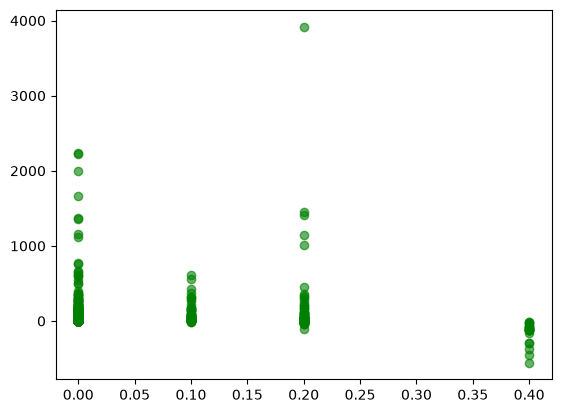

In [14]:
print("-= VIZUALIZATION =-")

ny_df = df[df["City"] == "New York City"]

corr = ny_df["Discount"].corr(ny_df["Profit"])
print("The correlation between Profit and Discount in New York: ", corr)

v_1 = plt.scatter(ny_df["Discount"], ny_df["Profit"], alpha=0.6, color="green")


-= VIZUALIZATION 2 =-


<Figure size 800x500 with 0 Axes>

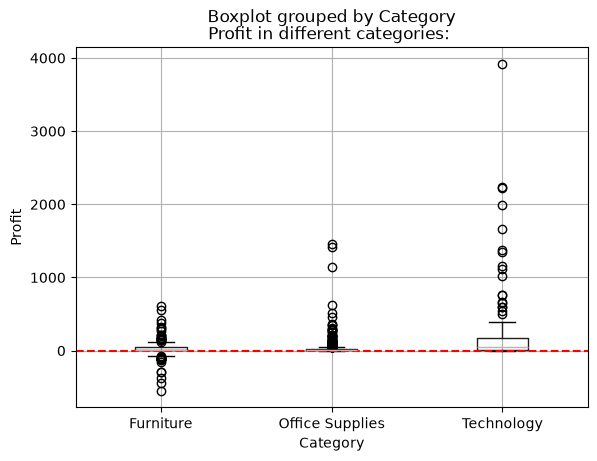

In [15]:
print("-= VIZUALIZATION 2 =-")

plt.figure(figsize=(8, 5))
ny_df.boxplot(column="Profit", by="Category")
plt.title("Profit in different categories: ")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.axhline(0, color="red", linestyle="--")
plt.show()

-= MONTH VIZUALIZATION =-


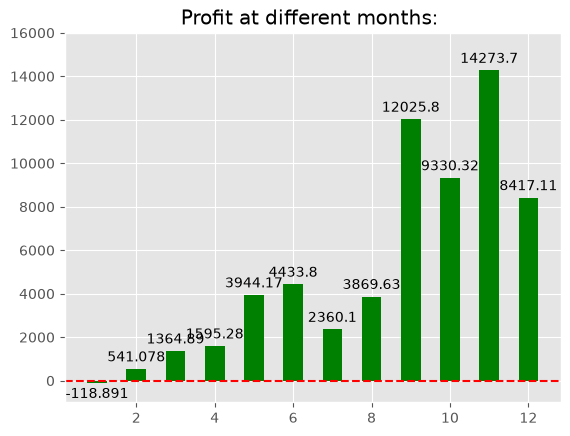

In [16]:
print("-= MONTH VIZUALIZATION =-")

ny_dfx = ny_df.groupby("Month", as_index=False)["Profit"].sum()

plt.style.use("ggplot")
bars = plt.bar(ny_dfx["Month"], ny_dfx["Profit"], color="green", width=0.5)
plt.bar_label(bars, padding=3)
plt.ylim(-1000, 16000)
plt.axhline(0, color="red", linestyle="--")
plt.title("Profit at different months: ")
plt.show()


-= WEEK DAYS VIZUALIZATION =-


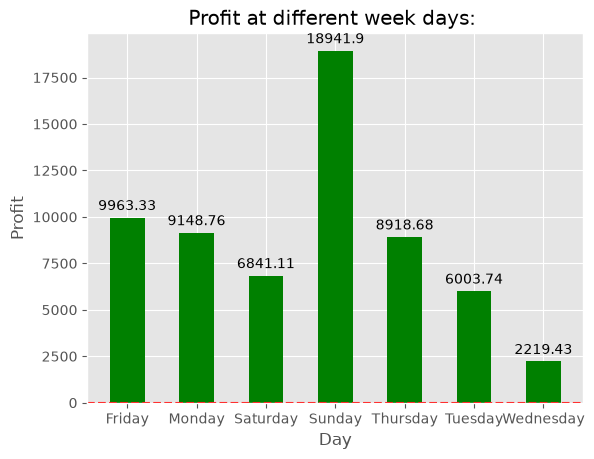

In [17]:
print("-= WEEK DAYS VIZUALIZATION =-")

ny_dfy = ny_df.groupby("Day", as_index=False)["Profit"].sum()

plt.style.use("ggplot")
bars2 = plt.bar(ny_dfy["Day"], ny_dfy["Profit"], color="green", width=0.5)
plt.bar_label(bars2, padding=3)
plt.ylabel("Profit")
plt.xlabel("Day")
plt.axhline(0, color="red", linestyle="--")
plt.title("Profit at different week days: ")
plt.show()

**CONCLUSIONS AND INFORMATION:**
--- TARGET: Understanding what exactly drives the profit, what cities generate the highest returns, and what factors cause profit fluctuations...
_________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
**Profit information:** Quantity - 9994; MEAN profit(1 customer) - 28$; SD - 234; MIN - -6599$(lesion); MAX - 8399$; ALL Profit - 286.397$; QUANTILE 1(25%) - 1.7$; MEDIAN - 8.6$; QUANTILE 2(75%) - 29.3$...
**Discount information:** MEAN - 15%; SD - 20%; MAX - 80%...
_________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
**DAY-table:** The most *profitable day* - (Purchases - Monday; Total profit - Sunday; Average profit - Wednesday). ---> Sunday(18.900$) and Wednesday(2.200$) are interest for us stronger than other days...
**MONTH-table:** The most *profitable month* - (Purchases - November; Total profit - December; Average profit - March)...
_________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
**GEOGRAPHY information 1:** Top 4 most *profitable cities* - New York(T-profit - 62.000$; Average profit - 67$; Purchases - 915), Los Angeles(T-profit - 30.400$; Average profit - 40$, Purchases - 747),
Seattle(T-profit - 29.100$; Average-profit - 68$; Purchases - 428), Detroit(T-profit - 13.100$; Average profit - 114$; Purchases - 115)...
**GEOGRAPHY information 2:** Top 5 most *purchased cities* - New York(info above), Los Angeles(info above), Philadelphia(Purchases - 537; T-profit - -13.800$!; Average profit - -25$!),
San Francisco(Purchases - 510; T-profit - 17.500$; Average profit - 34$); Seattle(info above)...
Further, I will examine only New York because from my perspective this city is the most influential and interesting for the business...
_________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
**CATEGORY information:** Here are only 3 categories(main) - Technology, Furniture, Office Supplies; Purchased categories - Office supplies: 6.000 pur; Avg-profit - 20$; T-profit - 122.400$... -                                                                                                                         - Furniture: 2.100 pur; Avg-profit - 8$; T-profit - 18.451$...
-                                                                                                                         - Technology: 1.850 pur; Avg-profit - 78$; T-profit - 145.454$!...
_________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
**NEW YORK 1:** 3 most *purchased months* - September(160), November(155), December(130); 3 most purchased days - Monday(175; T-profit - 9.100$), Friday(174; T-profit - 9.900$) Sunday(165; T-profit - 18.900$);
Most purchased category - O.Supplies(552, T-profit - 20.600$, Avg - 37$) and Furniteure + Technology are beneath, it is important to notice that Technology was purchased only 171 time, the profit is 36.100$! And avg - 211$,
so, we will examine the techonogy further because we are interesting in profit...
__________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
**NEW YORK 2:** The most *purchased sub-category* is "Phones", beneath are - Accessories(64; T-p - 5.000$;  Avg - 78$),           - Despite Machines having the highest profit, I think that it is more difficult to influence the customers to buy the machines,
                                                                           Machines(   12  T-p - 14.500$; Avg - 1.200$),   ---> - so the profit may be very unstable. But customers Are buying the phones more often, the profit is not small and is more stable,
                                                                           Copiers(    6;  T-p - 5700$;   Avg - 950$)...        - it is easier to influence the customers, so I think that it is better to spend more attention on "Phones" sub-category...
I checked the information about profit and purchases in "Office Supplies", too, and I notised that customers often buy "binders"(145; T-p - 8.300$; Avg - 57$), it is important to take this into account, too because the profit is almost like the profit from phones. 
__________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
**NEW YORK 3:** Table_1 - Days of purchase in New York do NOT DEVIATE from other cities(P-value - 0.29...), but the Cramer´s V is 0.01(small)         ---> So, the "Day" influence, likely is an accident, but there is a month influence, but the inluence is very small.
                Table_2 - Months of purchase in New York DEVIATE from other cities(P-value - 0.0001...), but the Cramer´s V is only 0.04(small, too)  ---> The influence of time is not interest for us, it has too little effect.(For profit)
__________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
**NEW YORK 4, BIG TABLE:** "Consumer"-segment WITHOUT discount has the highest quantity of purchases, profit and one of highest avg_profit!(T-profit - 8.300$; Avg - 64$)...
Looking at the table, we can conclude that: "The less the discount, the higher is the total profit", also: "The higher the discount, the less purchases and more losses we have"...
So, if product has not any discount, we receive the highest profit. Discount - +-20%, we still receive enough big profit, but it is less than withot discount. Discount - +-50%, here are most of lesions, Average profit is +- -95$ in all of the segments.
__________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
**CORR VIZUALIZATION:** There are only 10, 20 and 40% discounts in New York. Profit at discounts up to 20% is the highest, losses are not so much, but at 40% discount we see many losses and the smalest profit, it is on average near 0-profit. "Without discount" and
20% discount show best profit. The CORRELATION is -0.06...
__________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
**BOXPLOT VIZUALIZATION:** Examination of the categories ---> "Furniture is the most lossed category, many lesions and profit even does not rise to 800$"...
                                                         ---> "Office supllies-category is the most stable and purchased category, looking at the outcomes of studying it is the most perspective category, as I think.
                                                               Also there is not lesions(according to the vizualzation)", the profit rarely rises up to 1000$...
                                                         ---> "Technology is the most profitable category, there is not any lesions(according to the vizualization), the category is not stable, the profit rises up to
                                                               4000$(1 purchase!; Mostly it rises up to 2000$)...
__________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
**MONTH VIZUALIZATION:** Examining the vizualization: ---> "The vizualization shows obviously that the profit is greatest in September - December, and in November the profit is the highest(14.000$), but in January it 
                                                            decreases up to a losses(-100$), but then it grows up gradually, falls in the mibble of the summer, then it grows up suddenly as I said...
                                                      -> Maybe, the reason is holidays and special days, but of course these are not all the reasons that influence the profit... 
__________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
**WEEK DAYS VIZUALIZATION:** Studying the week days: ---> As I said Sunday is the profitable day, surprisigly the profit is figher than in all other days in two or more times...
Friday, Monday and Thursday have almost the same profit(9.000$; Avg!), in Saturday and Thuesday it becomes smaler on several thousands dollars, and in Wednesday the profit is smalest(2.200$!) for some reason...
Sunday is a weekend usually, people usually want to rent, shop something they wanted, when they have the ability, maybe these factors influence the profit. But anyway as of now we have not evough of evidence to claim it...
__________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________

**MY ADVICES:** ---> 1. Start open in Sunday earlier and work longer, because in this day the profit is usually the highest, let the customers to buy products they want...
                ---> 2. Try to keep the discounts smaller than 20%, especially in Sunday...
                ---> 3. Recognise the real reason why do the customers buy so much products in Sunday, and what does happen in Wednesday...
                ---> 4. Pay your attention the Autumn-Winter´s months, more advertisements, longer work-time and so on...
                ---> 5. Sell more Technology and Office-Supplies-Products category´s products! Especially O-Supplies-Products, there it is easier to influence the customers,
                        at the same time do not forget the Technology-category. Less Furniture_category´s productsprocurement, it is unperspective category...
                ---> 6. Try to decrease the quantity of big discounts, they are mostly unprofitable(Especially 40%-discount)...
                ---> 7. Pay your attention to holidays and other factors that could influence the profit, study it and make next decisions on this ground...
__________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
# DATA about the dataset: Name - SuperStore; The dataset contains only purchase-customers, only from United States; Dataset - 2014-2017 year(3-4); Products - Technology, Furniture and Office supplies; The dataset is from kaggle.com...

#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- 